# Forecasting Notebook — Revenue & Units

**Goals**
- Aggregate to daily / weekly / monthly
- Train baseline models: seasonal naive, ARIMA, Prophet (optional)
- Forecast revenue and units


In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', context='talk')
plt.rcParams['figure.figsize'] = (14, 6)

DATA_PATH = '/kaggle/input/amazon-sales-dataset/amazon_sales_dataset.csv'


In [2]:
df = pd.read_csv(DATA_PATH)
df['order_date'] = pd.to_datetime(df['order_date'], errors='coerce')

# Core metrics
for c in ['total_revenue','quantity_sold']:
    df[c] = pd.to_numeric(df[c], errors='coerce')

assert df['order_date'].isna().sum() == 0, 'Found unparsable dates.'

# Aggregations (make series continuous)
daily_raw = df.groupby('order_date', as_index=False).agg(
    revenue=('total_revenue','sum'),
    units=('quantity_sold','sum')
).sort_values('order_date')

full_daily_idx = pd.date_range(daily_raw['order_date'].min(), daily_raw['order_date'].max(), freq='D')
agg_daily = (
    daily_raw.set_index('order_date')
    .reindex(full_daily_idx)
    .fillna(0)
    .rename_axis('order_date')
    .reset_index()
)

# Weekly / Monthly from daily to ensure continuity
agg_weekly = (
    agg_daily.set_index('order_date')
    .resample('W-MON')
    .sum()
    .reset_index()
)

agg_monthly = (
    agg_daily.set_index('order_date')
    .resample('MS')
    .sum()
    .reset_index()
)

print('Daily rows:', len(agg_daily))
print('Weekly rows:', len(agg_weekly))
print('Monthly rows:', len(agg_monthly))

agg_daily.head()


Daily rows: 730
Weekly rows: 105
Monthly rows: 24


,order_date,revenue,units
0,2022-01-01,47860.37,196
1,2022-01-02,35499.55,161
2,2022-01-03,40929.87,199
3,2022-01-04,34813.73,167
4,2022-01-05,38316.72,205


## 1) Visualize aggregates


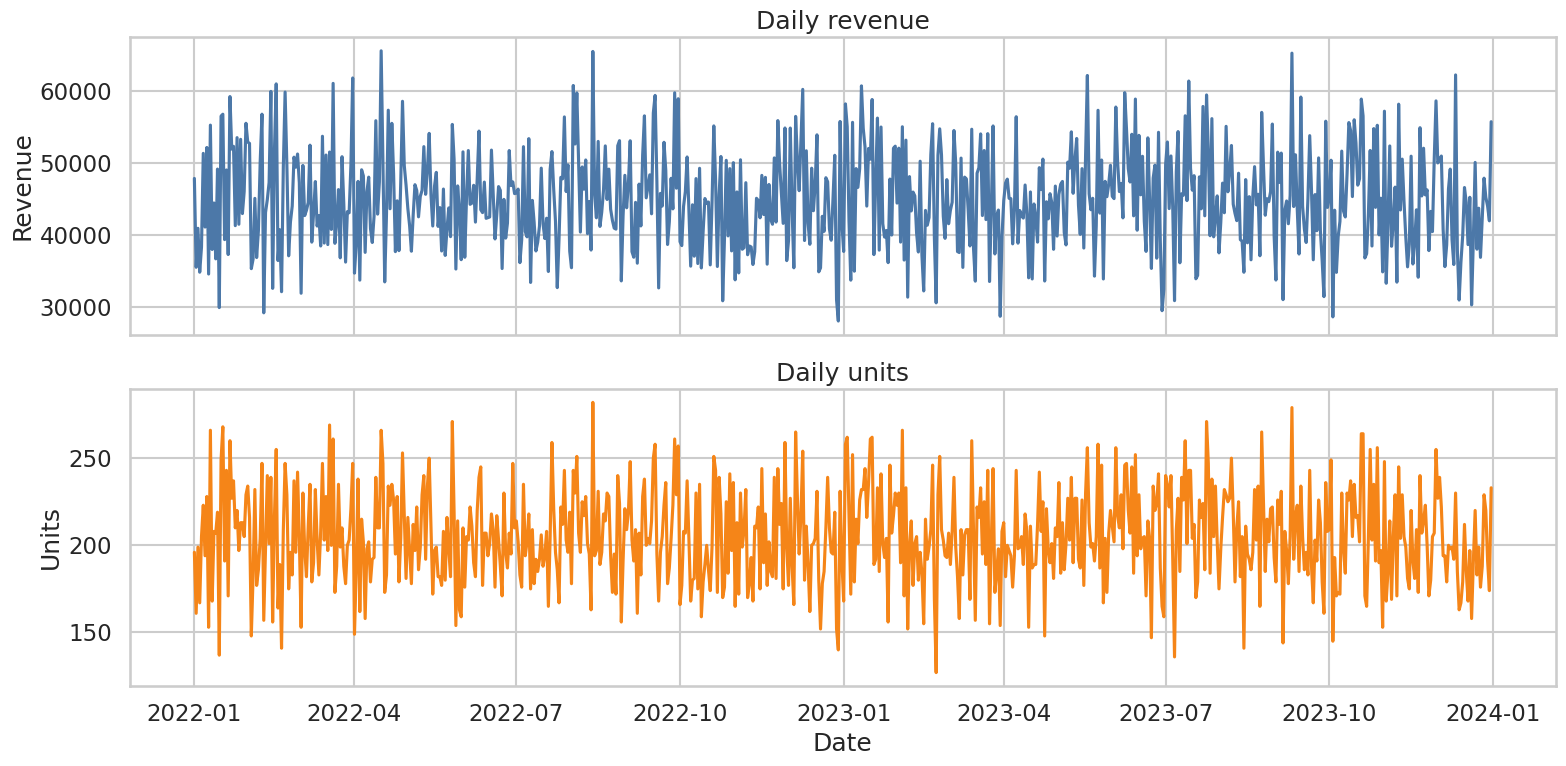

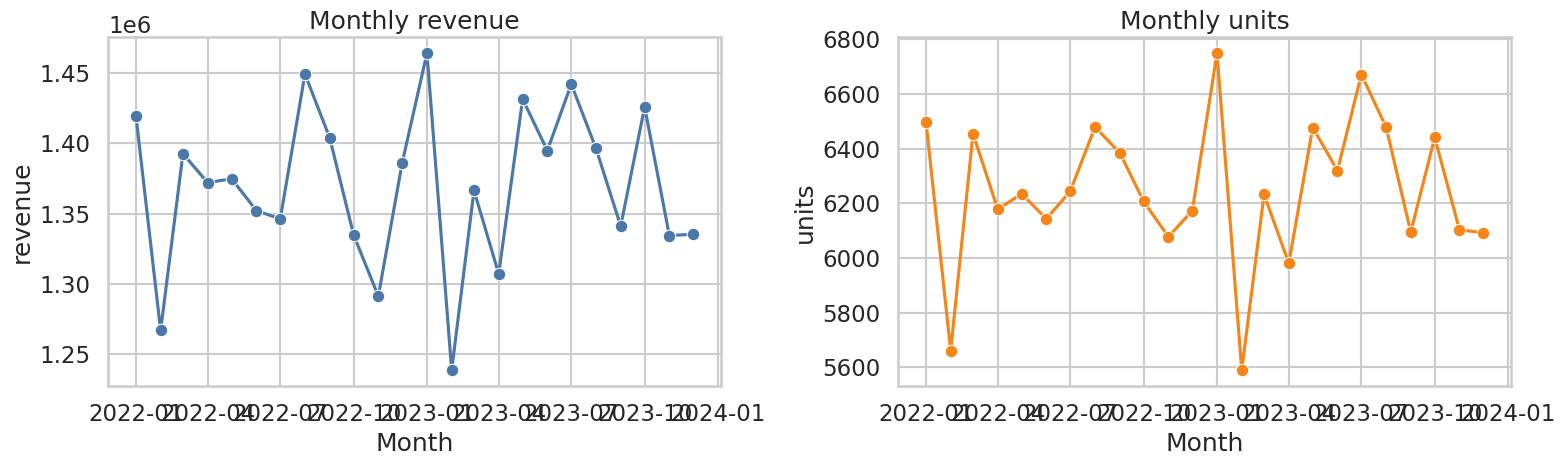

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(16, 8), sharex=True)

sns.lineplot(data=agg_daily, x='order_date', y='revenue', ax=axes[0], color='#4C78A8')
axes[0].set_title('Daily revenue')
axes[0].set_ylabel('Revenue')

sns.lineplot(data=agg_daily, x='order_date', y='units', ax=axes[1], color='#F58518')
axes[1].set_title('Daily units')
axes[1].set_ylabel('Units')
axes[1].set_xlabel('Date')

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.lineplot(data=agg_monthly, x='order_date', y='revenue', ax=axes[0], marker='o', color='#4C78A8')
axes[0].set_title('Monthly revenue')
axes[0].set_xlabel('Month')

sns.lineplot(data=agg_monthly, x='order_date', y='units', ax=axes[1], marker='o', color='#F58518')
axes[1].set_title('Monthly units')
axes[1].set_xlabel('Month')

plt.tight_layout()
plt.show()


## 2) Train/test split + metrics

We use a simple holdout split (last **N** periods) and evaluate with MAE/MAPE.


In [4]:
def train_test_split_ts(df, target_col, test_size):
    train = df.iloc[:-test_size].copy()
    test = df.iloc[-test_size:].copy()
    return train, test

def mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

def mape(y_true, y_pred):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    mask = y_true != 0
    return np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100

# Holdout sizes
TEST_DAILY = 60
TEST_WEEKLY = 12
TEST_MONTHLY = 6


## 3) Baseline model: Seasonal Naive

Forecast each period using the value from the same season last year.
- Daily seasonality: 365
- Weekly seasonality: 52
- Monthly seasonality: 12


In [5]:
def seasonal_naive_forecast(train, test, target_col, season_length):
    # Use last season values for forecast; fallback if season is longer than train
    season_length = min(season_length, len(train))
    if season_length == 0:
        return np.zeros(len(test))
    last_season = train[target_col].iloc[-season_length:].values
    reps = int(np.ceil(len(test) / season_length))
    forecast = np.tile(last_season, reps)[:len(test)]
    return forecast

# Daily
train_d, test_d = train_test_split_ts(agg_daily, 'revenue', TEST_DAILY)
fc_d_rev = seasonal_naive_forecast(train_d, test_d, 'revenue', season_length=365)

train_d_u, test_d_u = train_test_split_ts(agg_daily, 'units', TEST_DAILY)
fc_d_units = seasonal_naive_forecast(train_d_u, test_d_u, 'units', season_length=365)

print('Daily revenue - MAE:', mae(test_d['revenue'], fc_d_rev), 'MAPE:', mape(test_d['revenue'], fc_d_rev))
print('Daily units   - MAE:', mae(test_d_u['units'], fc_d_units), 'MAPE:', mape(test_d_u['units'], fc_d_units))

# Weekly
train_w, test_w = train_test_split_ts(agg_weekly, 'revenue', TEST_WEEKLY)
fc_w_rev = seasonal_naive_forecast(train_w, test_w, 'revenue', season_length=52)

train_w_u, test_w_u = train_test_split_ts(agg_weekly, 'units', TEST_WEEKLY)
fc_w_units = seasonal_naive_forecast(train_w_u, test_w_u, 'units', season_length=52)

print('Weekly revenue - MAE:', mae(test_w['revenue'], fc_w_rev), 'MAPE:', mape(test_w['revenue'], fc_w_rev))
print('Weekly units   - MAE:', mae(test_w_u['units'], fc_w_units), 'MAPE:', mape(test_w_u['units'], fc_w_units))

# Monthly
train_m, test_m = train_test_split_ts(agg_monthly, 'revenue', TEST_MONTHLY)
fc_m_rev = seasonal_naive_forecast(train_m, test_m, 'revenue', season_length=12)

train_m_u, test_m_u = train_test_split_ts(agg_monthly, 'units', TEST_MONTHLY)
fc_m_units = seasonal_naive_forecast(train_m_u, test_m_u, 'units', season_length=12)

print('Monthly revenue - MAE:', mae(test_m['revenue'], fc_m_rev), 'MAPE:', mape(test_m['revenue'], fc_m_rev))
print('Monthly units   - MAE:', mae(test_m_u['units'], fc_m_units), 'MAPE:', mape(test_m_u['units'], fc_m_units))


Daily revenue - MAE: 7552.966333333333 MAPE: 17.784245054713075
Daily units   - MAE: 28.8 MAPE: 14.453388432017315
Weekly revenue - MAE: 26292.882500000007 MAPE: 8.46849909805828
Weekly units   - MAE: 86.75 MAPE: 6.169073445100915
Monthly revenue - MAE: 66233.94666666666 MAPE: 4.7672610024873014
Monthly units   - MAE: 176.16666666666666 MAPE: 2.7553977677577413


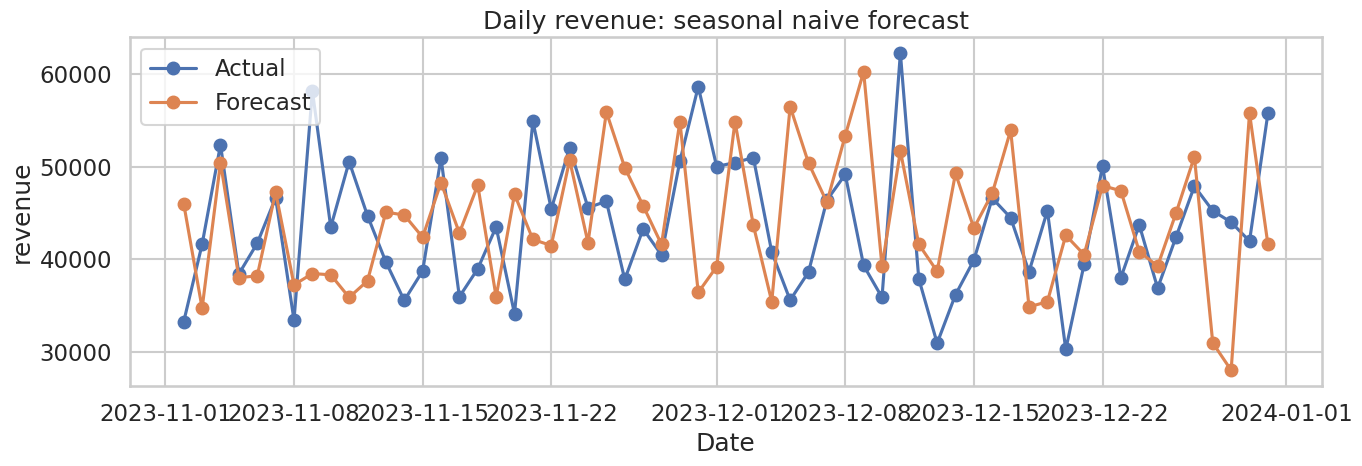

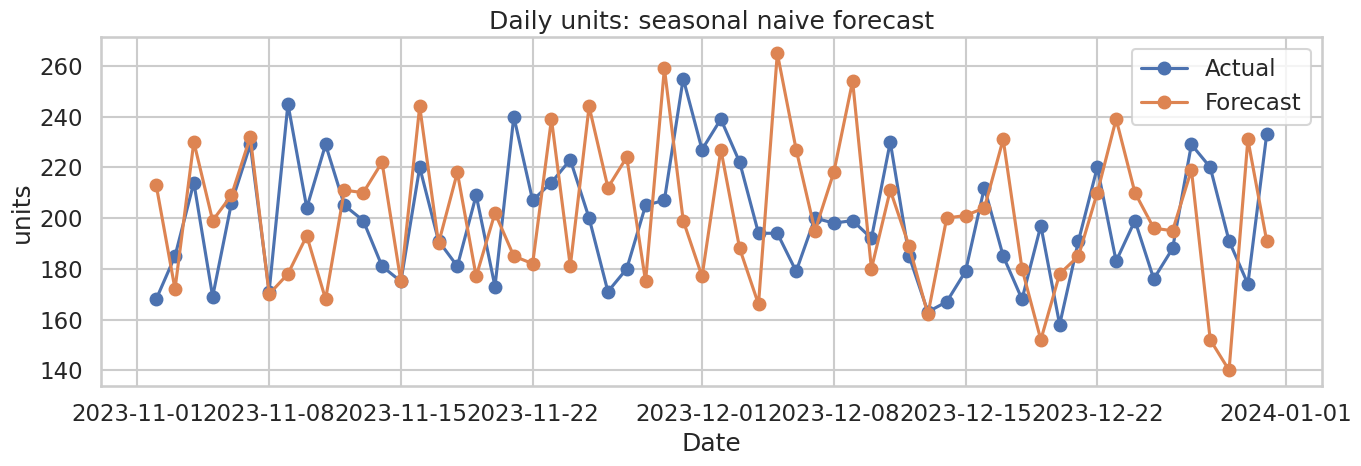

In [6]:
def plot_forecast(test_df, forecast, title, target_col):
    plt.figure(figsize=(14, 5))
    plt.plot(test_df['order_date'], test_df[target_col], label='Actual', marker='o')
    plt.plot(test_df['order_date'], forecast, label='Forecast', marker='o')
    plt.title(title)
    plt.xlabel('Date')
    plt.ylabel(target_col)
    plt.legend()
    plt.tight_layout()
    plt.show()

plot_forecast(test_d, fc_d_rev, 'Daily revenue: seasonal naive forecast', 'revenue')
plot_forecast(test_d_u, fc_d_units, 'Daily units: seasonal naive forecast', 'units')


## 4) ARIMA baseline (optional)

Uses `statsmodels` SARIMAX. If not installed, this section will be skipped.


ARIMA daily revenue - MAE: 7001.053273604944 MAPE: 17.604021020288307


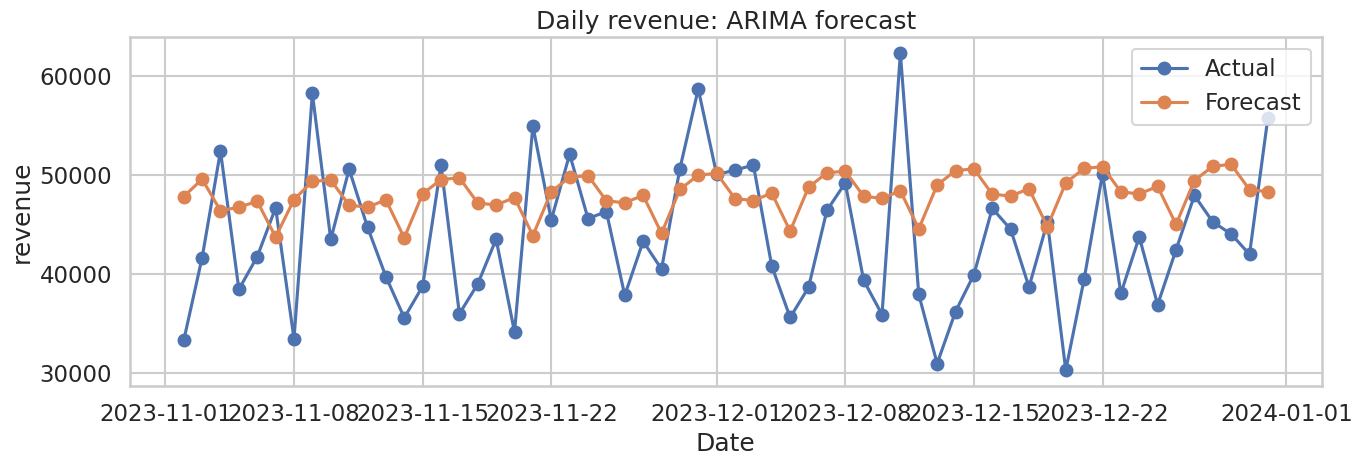

In [7]:
try:
    from statsmodels.tsa.statespace.sarimax import SARIMAX

    def fit_arima_forecast(train_df, test_df, target_col, order=(1,1,1), seasonal_order=(1,1,1,7)):
        model = SARIMAX(train_df[target_col], order=order, seasonal_order=seasonal_order, enforce_stationarity=False, enforce_invertibility=False)
        res = model.fit(disp=False)
        fc = res.forecast(steps=len(test_df))
        return fc

    # Example: daily revenue with weekly seasonality
    arima_fc = fit_arima_forecast(train_d, test_d, 'revenue', order=(1,1,1), seasonal_order=(1,1,1,7))
    print('ARIMA daily revenue - MAE:', mae(test_d['revenue'], arima_fc), 'MAPE:', mape(test_d['revenue'], arima_fc))
    plot_forecast(test_d, arima_fc, 'Daily revenue: ARIMA forecast', 'revenue')

except Exception as e:
    print('ARIMA skipped:', e)


## 5) Prophet baseline (optional)

Prophet is great for business time-series. If not installed, this section is skipped.


02:04:14 - cmdstanpy - INFO - Chain [1] start processing
02:04:14 - cmdstanpy - INFO - Chain [1] done processing


Prophet daily revenue - MAE: 6022.602694972726 MAPE: 14.633824606003115


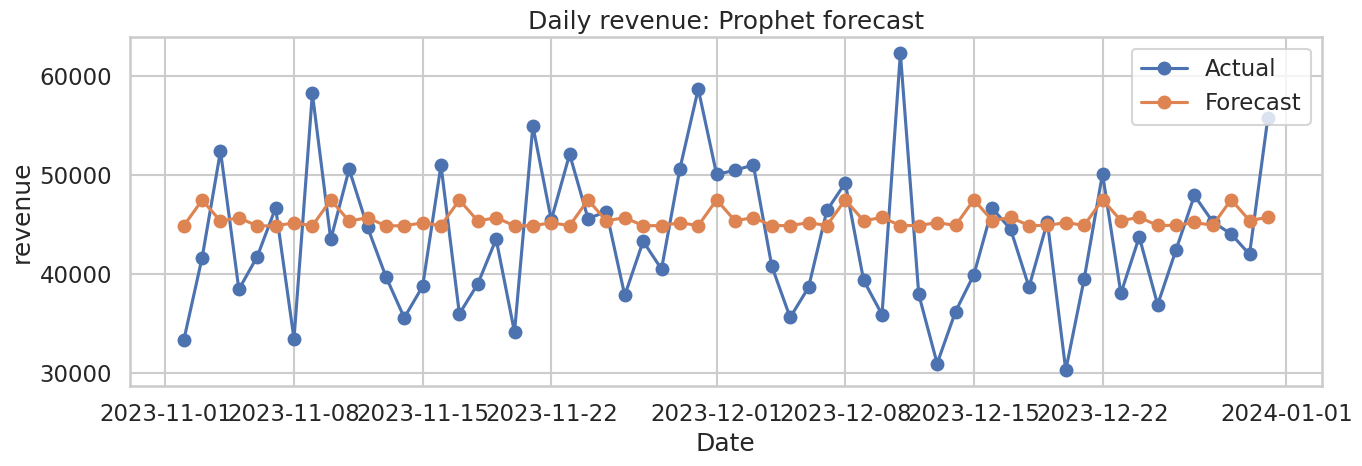

In [8]:
try:
    from prophet import Prophet

    def fit_prophet_forecast(train_df, test_df, target_col):
        dfp = train_df[['order_date', target_col]].rename(columns={'order_date':'ds', target_col:'y'})
        m = Prophet()
        m.fit(dfp)
        future = m.make_future_dataframe(periods=len(test_df), freq='D')
        fc = m.predict(future)
        return fc.tail(len(test_df))['yhat'].values

    prophet_fc = fit_prophet_forecast(train_d, test_d, 'revenue')
    print('Prophet daily revenue - MAE:', mae(test_d['revenue'], prophet_fc), 'MAPE:', mape(test_d['revenue'], prophet_fc))
    plot_forecast(test_d, prophet_fc, 'Daily revenue: Prophet forecast', 'revenue')

except Exception as e:
    print('Prophet skipped:', e)
